# Análisis del catálogo de FAV

**Trabajo Práctico Integrador · Base de Datos Aplicada · consigna 5.7**

FAV es una tienda de ropa que suma la venta online. Este notebook analiza el catálogo guardado en MongoDB (colecciones `productos`, `categorias` y `promociones`) para responder cuatro preguntas del negocio:

1. ¿Dónde está concentrado el precio?
2. ¿Dónde es más amplia la oferta?
3. ¿Qué se promociona y qué no?
4. ¿Falta variedad en algún talle o color?

**Qué no se analiza:** stock ni rotación. El stock vive en el servicio de Inventario (MySQL), no en esta base (decisión D1 de `PROYECTO.md`).

**Cómo se corre:** con la base levantada y cargada (`docker compose up -d` y `docker compose run --rm cargador`, desde `tp-mongo/`). Las credenciales se leen de `tp-mongo/.env`; no están escritas en el notebook.

## 1. Conexión y recuperación de los datos

In [1]:
import os
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from matplotlib.ticker import FuncFormatter
from pymongo import MongoClient

# Credenciales del .env de tp-mongo. MONGO_HOST permite correr el notebook dentro de Docker
# (mongo-catalogo:27017); por defecto usa el puerto que el Compose del TP publica en la PC.
load_dotenv(Path.cwd().parent / ".env")
cliente = MongoClient(
    os.environ.get("MONGO_HOST", "localhost:27017"),
    username=os.environ["MONGO_INITDB_ROOT_USERNAME"],
    password=os.environ["MONGO_INITDB_ROOT_PASSWORD"],
    authSource="admin",
    serverSelectionTimeoutMS=5000,
)
db = cliente[os.environ.get("MONGO_DB", "catalogo")]
cliente.admin.command("ping")

# "Hoy" es fijo (el día de la defensa) para que el análisis de promociones sea reproducible.
HOY = datetime(2026, 11, 3, 15, 0, tzinfo=timezone.utc)  # 03/11/2026, 12:00 de Argentina

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
def ars(monto, decimales=0):
    # Formato argentino: punto de miles y coma decimal ($34.338,88).
    texto = f"{monto:,.{decimales}f}".replace(",", "@").replace(".", ",").replace("@", ".")
    return f"${texto}"

pesos = FuncFormatter(lambda x, _: ars(x))

print("Documentos por colección:", {c: db[c].count_documents({}) for c in ["categorias", "productos", "promociones"]})

Documentos por colección: {'categorias': 13, 'productos': 252, 'promociones': 14}


In [2]:
# Solo los campos que usa el análisis (proyección): no se traen fotos ni descripciones.
documentos = list(db.productos.find(
    {}, {"nombre": 1, "categoria": 1, "sistemaTalles": 1, "precioBase.monto": 1, "publicado": 1, "variantes": 1}
))
nombre_categoria = {c["_id"]: c["nombre"] for c in db.categorias.find()}

productos = pd.DataFrame([{
    "productoId": d["_id"],
    "nombre": d["nombre"],
    "categoria": nombre_categoria[d["categoria"]],
    "sistema": d["sistemaTalles"],
    "centavos": int(d["precioBase"]["monto"]),
    "publicado": d["publicado"],
    "variantes": len(d["variantes"]),
} for d in documentos])
productos.head()

,productoId,nombre,categoria,sistema,centavos,publicado,variantes
0,prod-remera-basica,Remera básica,Remeras,LETRAS,1500000,True,2
1,prod-jean-mom,Jean mom,Jeans,NUMERICO_PAR,4200000,True,1
2,prod-top-de-breteles-con-volados,Top de breteles con volados,Tops,NUMERICO_1_4,1199000,False,2
3,prod-top-corto-acanalado,Top corto acanalado,Tops,NUMERICO_1_4,1850000,True,1
4,prod-top-de-breteles-con-lazo,Top de breteles con lazo,Tops,NUMERICO_1_4,1349000,True,3


## 2. Preparación de los datos

- Los montos se guardan en **centavos enteros** (D13): se pasan a pesos solo para mostrar.
- El análisis usa los productos **publicados**, que son los que ve el cliente en la web. Los despublicados se informan aparte.
- Las variantes están **embebidas** en cada producto: para contarlas por talle y color se "abren" en una fila por variante, lo mismo que hace `$unwind` en MongoDB.

In [3]:
productos["precio"] = productos["centavos"] / 100
publicados = productos[productos["publicado"]].copy()

variantes = pd.DataFrame([
    {"productoId": d["_id"], "categoria": nombre_categoria[d["categoria"]], "sistema": d["sistemaTalles"],
     "talle": v["talle"], "color": v["color"]}
    for d in documentos if d["publicado"] for v in d["variantes"]
])

resumen = pd.Series({
    "Productos en la base": len(productos),
    "Productos publicados": len(publicados),
    "Productos despublicados": int((~productos["publicado"]).sum()),
    "Variantes publicadas": len(variantes),
    "Variantes por producto publicado (promedio)": round(len(variantes) / len(publicados), 2),
    "Precio base promedio publicado": ars(publicados["precio"].mean(), 2),
}, name="Valor")
resumen.to_frame()

,Valor
Productos en la base,252
Productos publicados,205
Productos despublicados,47
Variantes publicadas,703
Variantes por producto publicado (promedio),3.43
Precio base promedio publicado,"$34.338,88"


### Precio vigente con promociones

Para el indicador de promociones se usa el mismo pipeline de agregación que la **consulta 7** (`consultas/consultas.js`): por cada producto publicado, `$lookup` busca en `promociones` las vigentes hoy que lo alcanzan (por id, por categoría o a toda la tienda) y que valen para el medio de pago; se queda con la de mayor porcentaje (no se acumulan, D3).

Se toma el medio de pago por defecto, **transferencia** (D4), que es el precio que ve el cliente en la web. Las promociones de efectivo solo se aplican en el local y no cambian ese precio.

In [4]:
def precio_vigente(fecha, medio_pago):
    return [
        {"$lookup": {
            "from": "promociones",
            "let": {"productoId": "$_id", "categoria": "$categoria"},
            "pipeline": [
                {"$match": {"$expr": {"$and": [
                    {"$lte": ["$vigencia.desde", fecha]},
                    {"$gte": ["$vigencia.hasta", fecha]},
                    {"$or": [
                        {"$eq": ["$alcance.tipo", "TIENDA"]},
                        {"$and": [{"$eq": ["$alcance.tipo", "CATEGORIA"]}, {"$in": ["$$categoria", "$alcance.ids"]}]},
                        {"$and": [{"$eq": ["$alcance.tipo", "PRODUCTO"]}, {"$in": ["$$productoId", "$alcance.ids"]}]},
                    ]},
                    {"$or": [{"$eq": ["$tipo", "PORCENTAJE"]}, {"$eq": ["$medioPago", medio_pago]}]},
                ]}}},
                {"$sort": {"porcentaje": -1, "_id": 1}},  # gana la de mayor porcentaje (D3)
                {"$limit": 1},
            ],
            "as": "promocion",
        }},
        {"$project": {
            "categoria": 1,
            "centavos": "$precioBase.monto",
            "promocion": {"$first": "$promocion.nombre"},
            "porcentaje": {"$ifNull": [{"$first": "$promocion.porcentaje"}, 0]},
        }},
    ]

vigentes = pd.DataFrame(db.productos.aggregate([{"$match": {"publicado": True}}, *precio_vigente(HOY, "TRANSFERENCIA")]))
vigentes["categoria"] = vigentes["categoria"].map(nombre_categoria)
vigentes["centavos"] = vigentes["centavos"].astype("int64")
# Precio vigente en centavos enteros, truncado (D5): monto × (100 − porcentaje) / 100.
vigentes["vigente"] = (vigentes["centavos"] * (100 - vigentes["porcentaje"]) // 100) / 100
vigentes["conPromocion"] = vigentes["porcentaje"] > 0

print(f"{vigentes['conPromocion'].sum()} de {len(vigentes)} productos publicados tienen una promoción vigente "
      f"({vigentes['conPromocion'].mean():.0%})")
vigentes[vigentes["conPromocion"]].groupby("promocion").agg(
    productos=("_id", "count"), descuento=("porcentaje", "first")
).sort_values("productos", ascending=False)

73 de 205 productos publicados tienen una promoción vigente (36%)


,productos,descuento
promocion,,
Buzos y camperas de media estación,30,15
Semana de accesorios,23,25
Semana del jean,17,20
Liquidación de productos seleccionados,3,30


## 3. Indicadores

### Indicador 1 · Precio base promedio, mínimo y máximo por categoría

*Pregunta: ¿dónde está concentrado el precio?* La barra es el promedio y la línea va del producto más barato al más caro de cada categoría.

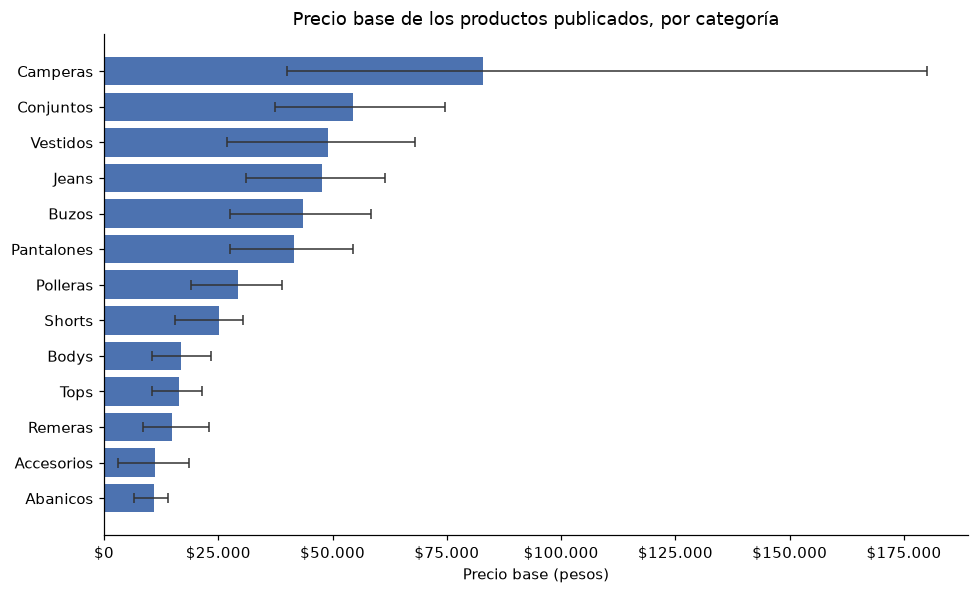

,productos,promedio,minimo,maximo
categoria,,,,
Camperas,13,82958.46,39990.0,180000.0
Conjuntos,11,54494.55,37490.0,74490.0
Vestidos,20,48944.50,27000.0,67990.0
Jeans,18,47773.33,30990.0,61490.0
Buzos,17,43612.94,27490.0,58500.0
Pantalones,22,41652.73,27490.0,54490.0
Polleras,16,29245.62,19000.0,38990.0
Shorts,12,25164.17,15490.0,30500.0
Bodys,12,16745.00,10490.0,23500.0


In [5]:
precios = publicados.groupby("categoria")["precio"].agg(productos="count", promedio="mean", minimo="min", maximo="max")
precios = precios.sort_values("promedio")

fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(precios))
ax.barh(y, precios["promedio"], color="#4C72B0")
ax.errorbar(precios["promedio"], y, xerr=[precios["promedio"] - precios["minimo"], precios["maximo"] - precios["promedio"]],
            fmt="none", ecolor="#333333", capsize=3, linewidth=1)
ax.set_yticks(y, precios.index)
ax.xaxis.set_major_formatter(pesos)
ax.set_xlabel("Precio base (pesos)")
ax.set_title("Precio base de los productos publicados, por categoría")
plt.tight_layout()
plt.show()

precios.sort_values("promedio", ascending=False).round(2)

**Qué muestra.** El precio se ordena en tres escalones:

- **Arriba de $40.000 de promedio:** camperas ($82.958), conjuntos ($54.495), vestidos ($48.945), jeans ($47.773), buzos ($43.613) y pantalones ($41.653).
- **Entre $25.000 y $30.000:** polleras y shorts.
- **Debajo de $17.000:** bodys, tops, remeras, accesorios y abanicos.

**Interpretación.** Camperas no es solo la categoría más cara: también es la de mayor dispersión, de $39.990 a $180.000. Ese máximo es un caso límite de los datos de prueba; sin él, el promedio de camperas bajaría a unos $74.900. En una categoría así conviene mirar el rango y no solo el promedio. En el otro extremo, accesorios y abanicos son de ticket bajo: suman a una compra más de lo que generan por sí solos.

### Indicador 2 · Productos y variantes publicados por categoría

*Pregunta: ¿dónde es más amplia la oferta?* Un producto es un modelo (por ejemplo, "Jean mom"); una variante es cada combinación de talle y color que se puede comprar.

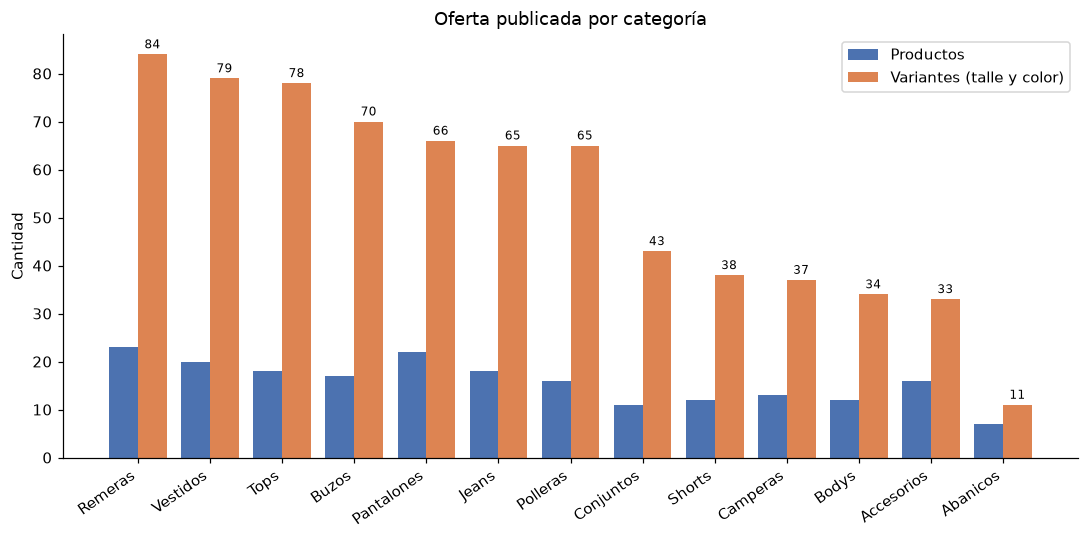

,productos,variantes,variantesPorProducto
categoria,,,
Remeras,23,84,3.7
Vestidos,20,79,4.0
Tops,18,78,4.3
Buzos,17,70,4.1
Pantalones,22,66,3.0
Jeans,18,65,3.6
Polleras,16,65,4.1
Conjuntos,11,43,3.9
Shorts,12,38,3.2


In [6]:
oferta = publicados.groupby("categoria").agg(productos=("productoId", "count"), variantes=("variantes", "sum"))
oferta["variantesPorProducto"] = (oferta["variantes"] / oferta["productos"]).round(1)
oferta = oferta.sort_values("variantes", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(oferta))
barras_p = ax.bar(x - 0.2, oferta["productos"], 0.4, label="Productos", color="#4C72B0")
barras_v = ax.bar(x + 0.2, oferta["variantes"], 0.4, label="Variantes (talle y color)", color="#DD8452")
ax.bar_label(barras_v, fontsize=8, padding=2)
ax.set_xticks(x, oferta.index, rotation=35, ha="right")
ax.set_ylabel("Cantidad")
ax.set_title("Oferta publicada por categoría")
ax.legend()
plt.tight_layout()
plt.show()

oferta

**Qué muestra.** Remeras es la categoría con más variantes publicadas (84), seguida de vestidos (79) y tops (78). Pantalones tiene casi tantos modelos como remeras (22 contra 23), pero menos variantes (66): ofrece muchos modelos con pocas combinaciones de talle y color, 3,0 por producto contra 4,3 de tops. Abanicos (1,6 variantes por producto) y accesorios (2,1) son talle único, así que su variedad viene solo del color. Camperas, la categoría más cara, tiene solo 37 variantes, 2,8 por producto.

**Interpretación.** La oferta más amplia está en los básicos de temporada (remeras, tops y vestidos), que son de los más baratos. Es razonable, porque son los que más se renuevan. En cambio, quien busca una campera, la compra de mayor valor, encuentra pocas opciones de talle y color por modelo.

### Indicador 3 · Porcentaje de productos con promoción vigente, por categoría

*Pregunta: ¿qué se promociona y qué no?* Productos publicados que hoy (03/11/2026) tienen un descuento pagando por transferencia, y el descuento promedio entre los que lo tienen.

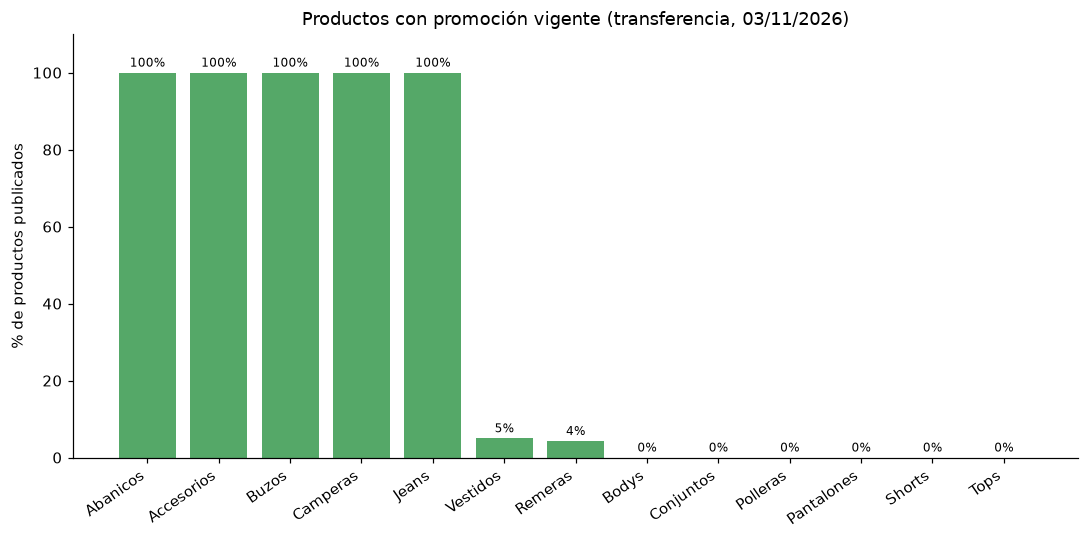

,productos,conPromocion,descuentoPromedio,porcentaje
categoria,,,,
Abanicos,7,7,25.0,100.0
Accesorios,16,16,25.0,100.0
Buzos,17,17,15.0,100.0
Camperas,13,13,15.0,100.0
Jeans,18,18,20.6,100.0
Vestidos,20,1,30.0,5.0
Remeras,23,1,30.0,4.3
Bodys,12,0,0.0,0.0
Conjuntos,11,0,0.0,0.0


In [7]:
promos = vigentes.groupby("categoria").agg(
    productos=("_id", "count"),
    conPromocion=("conPromocion", "sum"),
    descuentoPromedio=("porcentaje", lambda s: s[s > 0].mean() if (s > 0).any() else 0),
)
promos["porcentaje"] = (100 * promos["conPromocion"] / promos["productos"]).round(1)
promos = promos.sort_values("porcentaje", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.bar(promos.index, promos["porcentaje"], color="#55A868")
ax.bar_label(barras, labels=[f"{p:.0f}%" for p in promos["porcentaje"]], fontsize=8, padding=2)
ax.set_ylim(0, 110)
ax.set_ylabel("% de productos publicados")
ax.set_title("Productos con promoción vigente (transferencia, 03/11/2026)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

promos.round(1)

**Qué muestra.** 73 de los 205 productos publicados (36%) tienen hoy un descuento pagando por transferencia. Como las promociones son casi todas por categoría, el resultado es de "todo o nada":

- **Cinco categorías tienen el 100% de sus productos en promoción:** abanicos y accesorios (25%), jeans (20%), buzos y camperas (15%).
- **Seis no tienen ninguna:** bodys, conjuntos, polleras, pantalones, shorts y tops.
- **Vestidos y remeras tienen un solo producto cada una**, por la liquidación de productos seleccionados (30%).

**Interpretación.** Las promociones vigentes apuntan al abrigo (buzos y camperas), a los jeans y a los accesorios. Las prendas de primavera-verano (tops, shorts y polleras) no tienen ningún descuento en noviembre, y "Verano en remeras" recién empieza en diciembre. Vestidos sí tiene "15% en efectivo", pero ese descuento no se ve en el precio web porque solo vale pagando en efectivo.

**Límite.** Sin datos de ventas ni de stock, que están en otros servicios, no se puede saber si las categorías sin promoción la necesitan o si se venden bien igual.

### Indicador 4 · Variantes publicadas por talle y color

*Pregunta: ¿falta variedad en algún talle o color?* Cada celda cuenta cuántas variantes publicadas hay de ese talle en ese color. Las líneas verticales separan los sistemas de talles (letras, numérico par, numérico 1 a 4 y talle único).

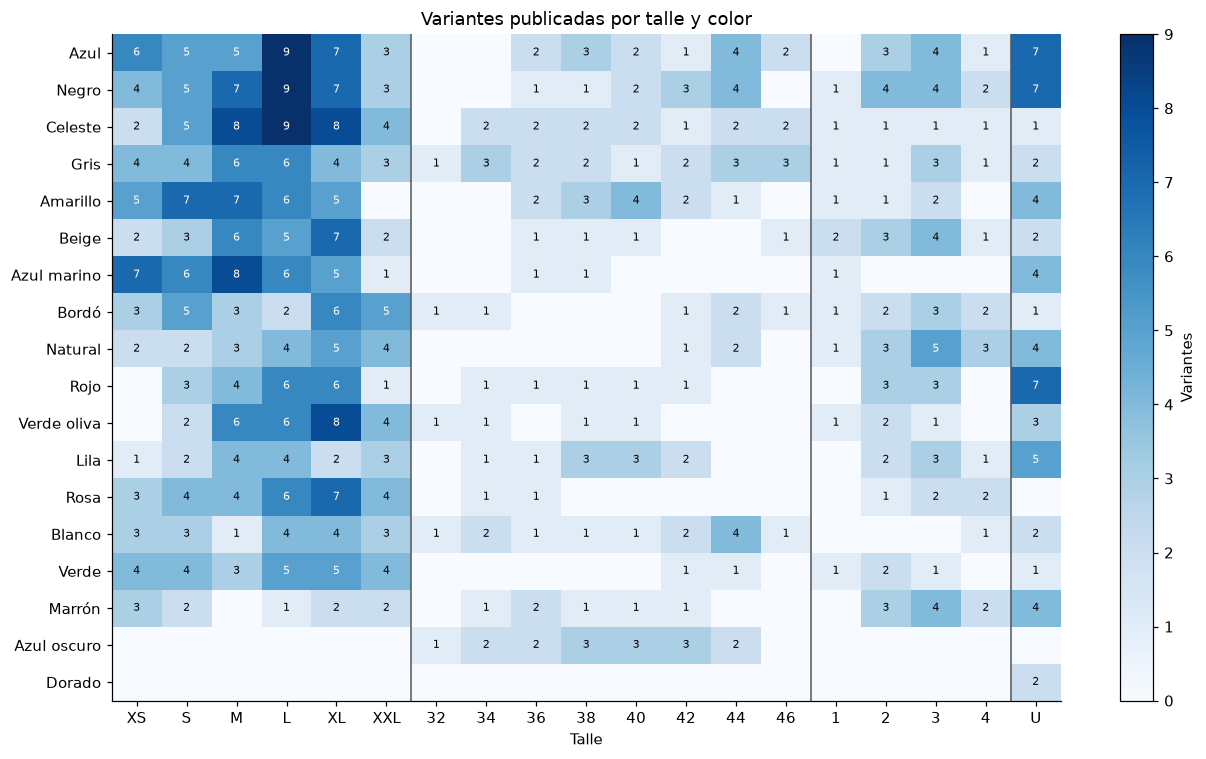

talle,XS,S,M,L,XL,XXL,32,34,36,38,40,42,44,46,1,2,3,4,U
variantes,49,62,75,88,88,46,5,15,19,23,22,21,25,10,11,31,40,17,56
sistema,LETRAS,LETRAS,LETRAS,LETRAS,LETRAS,LETRAS,NUMERICO_PAR,NUMERICO_PAR,NUMERICO_PAR,NUMERICO_PAR,NUMERICO_PAR,NUMERICO_PAR,NUMERICO_PAR,NUMERICO_PAR,NUMERICO_1_4,NUMERICO_1_4,NUMERICO_1_4,NUMERICO_1_4,UNICO


In [8]:
SISTEMAS = {
    "LETRAS": ["XS", "S", "M", "L", "XL", "XXL"],
    "NUMERICO_PAR": ["32", "34", "36", "38", "40", "42", "44", "46"],
    "NUMERICO_1_4": ["1", "2", "3", "4"],
    "UNICO": ["U"],
}
orden_talles = [t for talles in SISTEMAS.values() for t in talles]

tabla = pd.crosstab(variantes["color"], variantes["talle"]).reindex(columns=orden_talles, fill_value=0)
tabla = tabla.loc[tabla.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 7))
imagen = ax.imshow(tabla.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(tabla.columns)), tabla.columns)
ax.set_yticks(range(len(tabla.index)), tabla.index)
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        n = tabla.iat[i, j]
        if n:
            ax.text(j, i, n, ha="center", va="center", fontsize=7, color="white" if n > tabla.values.max() / 2 else "black")
corte = 0
for talles in list(SISTEMAS.values())[:-1]:
    corte += len(talles)
    ax.axvline(corte - 0.5, color="#555555", linewidth=1)
ax.set_xlabel("Talle")
ax.set_title("Variantes publicadas por talle y color")
fig.colorbar(imagen, ax=ax, label="Variantes")
plt.tight_layout()
plt.show()

por_talle = tabla.sum().rename("variantes").to_frame()
por_talle["sistema"] = [s for s, talles in SISTEMAS.items() for _ in talles]
por_talle.T

**Qué muestra.**

- **Talles de letras:** la oferta se concentra en L y XL (88 variantes cada uno) y en M (75). XS (49) y XXL (46) tienen cerca de la mitad.
- **Talles numéricos:** se repite el patrón. Del 38 al 44 hay entre 21 y 25 variantes por talle, pero el 32 tiene 5 y el 46 tiene 10.
- **Sistema 1 a 4:** el 3 (40) y el 2 (31) dominan sobre el 1 (11) y el 4 (17).

Hay además huecos puntuales: **Blanco**, un color básico, tiene una sola variante en talle M; **Marrón** no tiene ninguna en M; **Rosa** no aparece en talles numéricos del 38 para arriba. Azul oscuro y Dorado son colores de una sola categoría (jeans y abanicos).

**Interpretación.** La oferta acompaña a los talles del medio, pero deja cortos los extremos: quien usa XS, XXL, 32 o 46 encuentra muchas menos opciones. Los huecos en colores básicos, como el blanco en talle M, son los más fáciles de corregir, porque no requieren modelos nuevos: alcanza con agregar esa variante.

## 4. Conclusión y recomendación

**Resumen.**

- El catálogo publicado tiene 205 productos y 703 variantes, con un precio base promedio de $34.338,88.
- Precio y variedad van en sentidos opuestos: las categorías más baratas (remeras y tops) son las de más variantes, y la más cara (camperas) es de las que menos tienen.
- Las promociones vigentes cubren el 36% del catálogo publicado y se concentran en abrigo, jeans y accesorios.
- La oferta por talle se concentra en los del medio y deja cortos los extremos.

**Recomendaciones para FAV.**

1. **Lanzar una promoción de temporada en tops, shorts y polleras**, que hoy no tienen ningún descuento en plena primavera, en lugar de seguir promocionando abrigo, que sale de temporada. Alcanza con crear una promoción por categoría, sin tocar ningún producto: es una ventaja de tener las promociones en una colección aparte.
2. **Ampliar la variedad de camperas**, la categoría de mayor ticket y una de las de menos variantes por modelo.
3. **Completar los talles extremos y los colores básicos:** XS, XXL, 32 y 46, y el blanco en talle M.

**Límites.** El análisis usa datos de prueba generados con criterio realista (sección 8 de `PROYECTO.md`): las cifras ilustran el método, no la situación real de la tienda. Tampoco incluye ventas ni stock, que están en otros servicios (D1). Con esos datos se podría confirmar si las categorías sin promoción la necesitan, o si los talles extremos tienen poca oferta porque tienen poca demanda.

In [9]:
cliente.close()